In [4]:
!pip install matplotlib

In [5]:
import matplotlib 
print(matplotlib.__version__)

3.10.0


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv(r"C:\EXCEL DATA\Student_Analysis.csv")

In [8]:
df

,study_hours,student_marks
0,1.00,35.0
1,1.10,36.0
2,1.20,37.0
3,1.30,38.0
4,1.40,39.0
...,...,...
126,5.55,76.1
127,5.65,76.3
128,5.75,76.5
129,5.85,76.7


In [9]:
df.shape

(131, 2)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131 entries, 0 to 130
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   study_hours    131 non-null    float64
 1   student_marks  131 non-null    float64
dtypes: float64(2)
memory usage: 2.2 KB


In [11]:
df.describe()

,study_hours,student_marks
count,131.000000,131.000000
mean,4.427481,64.018321
std,2.177659,14.858879
min,1.000000,35.000000
25%,2.625000,51.250000
50%,4.250000,67.500000
75%,5.875000,76.750000
max,9.000000,86.000000


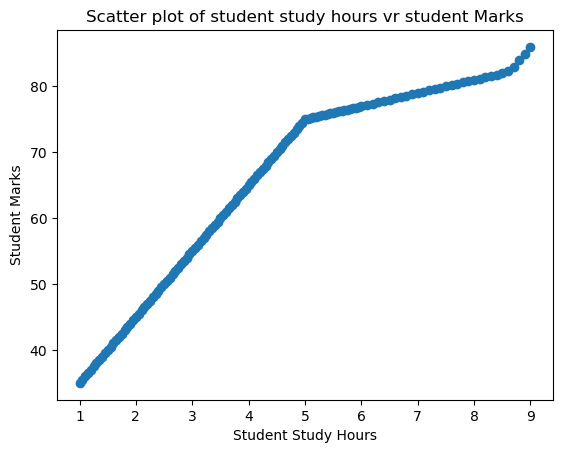

In [12]:
plt.scatter(x=df.study_hours, y =df.student_marks)
plt.xlabel("Student Study Hours")
plt.ylabel("Student Marks")
plt.title("Scatter plot of student study hours vr student Marks")
plt.show()

In [ ]:
# Data Cleaning


In [13]:
df.isnull().sum()

study_hours      0
student_marks    0
dtype: int64

In [14]:
df.mean()

study_hours       4.427481
student_marks    64.018321
dtype: float64

In [15]:
df2 = df.fillna(df.mean())

In [16]:
df.isnull().sum()

study_hours      0
student_marks    0
dtype: int64

In [17]:
df2.head()

,study_hours,student_marks
0,1.0,35.0
1,1.1,36.0
2,1.2,37.0
3,1.3,38.0
4,1.4,39.0


In [18]:
df.shape

(131, 2)

In [ ]:
#split dataset


In [20]:
x = df2.drop("student_marks", axis="columns")
y = df2.drop("study_hours", axis="columns")
print("shape of x = ", x.shape)
print("shape of y = ", y.shape)

shape of x =  (131, 1)
shape of y =  (131, 1)


In [21]:
x

,study_hours
0,1.00
1,1.10
2,1.20
3,1.30
4,1.40
...,...
126,5.55
127,5.65
128,5.75
129,5.85


In [22]:
y

,student_marks
0,35.0
1,36.0
2,37.0
3,38.0
4,39.0
...,...
126,76.1
127,76.3
128,76.5
129,76.7


In [23]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0)
print("shape of x_train = ", x_train.shape)
print("shape of y_train = ", y_train.shape)
print("shape of x_test = ", x_test.shape)
print("shape of y_test = ", y_test.shape)

shape of x_train =  (104, 1)
shape of y_train =  (104, 1)
shape of x_test =  (27, 1)
shape of y_test =  (27, 1)


In [24]:
x_train

,study_hours
118,4.75
68,7.80
16,2.60
96,2.55
122,5.15
...,...
128,5.75
123,5.25
67,7.70
117,4.65


In [25]:
x_test.shape

(27, 1)

In [26]:
y_train

,student_marks
118,72.5
68,80.6
16,51.0
96,50.5
122,75.3
...,...
128,76.5
123,75.5
67,80.4
117,71.5


In [ ]:
#select a model and train it

In [27]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [28]:
lr

LinearRegression()

In [29]:
lr.fit(x_train, y_train)

LinearRegression()

In [30]:
lr.coef_ #m

array([[6.513824]])

In [31]:
lr.intercept_ #c

array([35.30097872])

In [35]:
m = 6.51
c = 35.30
y = m * 2 + c
y

48.31999999999999

In [36]:
m = 6.51
c = 35.30
y = m * 11 + c
y

106.91

In [37]:
lr.predict([[11]]).round(2)

C:\Users\saipr\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([[106.95]])

In [38]:
y_pred = lr.predict(x_test)
y_pred

array([[47.02586191],
       [81.5491291 ],
       [48.00293551],
       [58.42505391],
       [88.0629531 ],
       [61.35627471],
       [70.4756283 ],
       [63.31042191],
       [80.8977467 ],
       [58.75074511],
       [92.6226299 ],
       [46.37447952],
       [56.14521551],
       [72.1040843 ],
       [48.32862671],
       [73.0811579 ],
       [57.77367151],
       [49.30570031],
       [43.11756752],
       [80.2463643 ],
       [75.6866875 ],
       [91.3198651 ],
       [57.44798031],
       [75.0353051 ],
       [74.3839227 ],
       [67.87009871],
       [44.74602352]])

In [41]:
pd.DataFrame(np.c_[x_test,y_test,y_pred], columns = ["study_hours", "student_marks_original", "student_marks_predicted"]) 

,study_hours,student_marks_original,student_marks_predicted
0,1.80,43.0,47.025862
1,7.10,79.2,81.549129
2,1.95,44.5,48.002936
3,3.55,60.5,58.425054
4,8.10,81.2,88.062953
5,4.00,65.0,61.356275
6,5.40,75.8,70.475628
7,4.30,68.0,63.310422
8,7.00,79.0,80.897747
9,3.60,61.0,58.750745


In [ ]:
#Fine Tune Your Model

In [42]:
lr

LinearRegression()

In [43]:
lr.score(x_test, y_test)


0.9167383002031556

In [44]:
lr.score(x_train, y_train)

0.9015598629697449

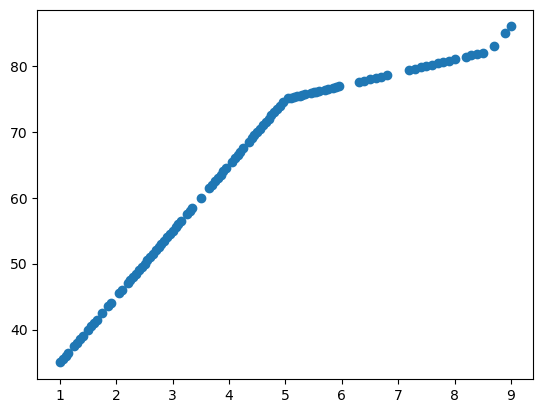

In [45]:
plt.scatter(x_train, y_train)

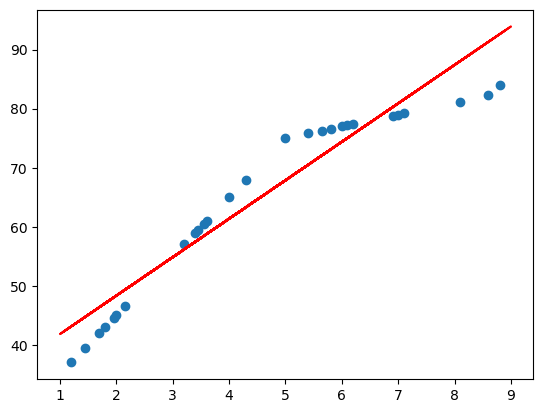

In [46]:
plt.scatter(x_test, y_test)
plt.plot(x_train, lr.predict(x_train), color = "r")

In [ ]:
#Present Your Solution


In [ ]:
#MOST IMP PART
# SAVE MI MODEL

In [48]:
import joblib # Create Pipeline
print(joblib.__version__)

1.4.2


In [49]:
lr

LinearRegression()

In [57]:
import joblib
joblib.dump(lr,"Student_Analysis.pkl")

['Student_Analysis.pkl']

In [59]:
model = joblib.load("Student_Analysis.pkl") #pickle

In [60]:
import os
os.getcwd()

'C:\\Users\\saipr'

In [ ]:
#Launch , Maintian and Monitor Your Model

In [ ]:
#To Create Front-end
# Use Flask for web framework
#web framework -  Flask
# Deployment - Streamlit, Heroku, Docker
# cloud -- AWS, AZURE, GCP
